# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

### 이 제출본의 실행 기준

- Chapter 06과 같은 Chapter 05 processed 네 파일을 사용하며, 없으면 먼저 과제 저장소의 Chapter 05 Notebook을 실행함
- 공식 Notebook의 실습 순서를 유지하고 필요한 함수는 아래 셀에 포함함
- 미연결 상품은 별도 그룹으로 보존하고 날짜 미상 금액은 월별 그래프 밖에서 합계를 확인함
- 공식 예제의 엄격한 미연결 중단 기준은 현재 데이터에 맞춰 미연결 현황을 공개하고 총액을 보존하는 방식으로 수정함

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

### 이번 과제의 대표 질문과 선택 이유

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 상세 금액은 얼마나 다른가? | 막대그래프 | 같은 단위의 범주별 크기를 0 기준에서 비교하기 쉬움 |
| 월별 completed 금액과 주문 수 차이는 어떻게 나타나는가? | 선그래프 | 시간 순서와 빈 기간을 확인하고 주문 수는 집계표로 비교할 수 있음 |
| 상품 마스터 가격은 어떤 범위에 분포하며 큰 값의 영향은 어떤가? | 히스토그램 | 구간별 상품 수와 전체·확대 범위를 비교할 수 있음 |


In [1]:
from pathlib import Path
import sys, json, hashlib, tempfile, subprocess, csv
from collections import defaultdict
from decimal import Decimal
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import StrMethodFormatter, MaxNLocator
from IPython.display import display

CURRENT_DIR = Path.cwd()
STUDY_ROOT = next((p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
                   if (p / 'chapter05/chapter05.ipynb').is_file()), None)
if STUDY_ROOT is None:
    raise FileNotFoundError('과제 저장소 루트 또는 chapter07 폴더에서 실행하세요')
PROJECT_ROOT = STUDY_ROOT.parent / 'llm-data-analysis-course'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports/chapter07'
FIGURE_DIR = STUDY_ROOT / 'chapter07/images'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
installed = {f.name for f in font_manager.fontManager.ttflist}
font = next((x for x in ['AppleGothic','Malgun Gothic','NanumGothic','Noto Sans CJK KR'] if x in installed), None)
if font is None: raise RuntimeError('한글 폰트를 확인하세요')
plt.rcParams.update({'font.family':font, 'axes.unicode_minus':False, 'figure.dpi':110})
print('입력: Chapter05 전용 raw를 처리한 인접 수업 폴더 data/processed')
print('그래프: chapter07/images, 집계표·보고서: 수업 폴더 reports/chapter07')
print('Python:',sys.version.split()[0], 'pandas:',pd.__version__, '한글 폰트:',font)

입력: Chapter05 전용 raw를 처리한 인접 수업 폴더 data/processed
그래프: chapter07/images, 집계표·보고서: 수업 폴더 reports/chapter07
Python: 3.12.14 pandas: 3.0.5 한글 폰트: AppleGothic


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [2]:
# Chapter05 처리 결과를 재생성하여 현재 입력 파일과 비교함
required_files = [PROCESSED_DIR / f'{name}_clean.csv' for name in ['customers','products','orders','order_items']]
assert all(p.is_file() for p in required_files), 'Chapter05 processed 네 파일이 필요함'
# Chapter 05 Notebook 함수로 임시 생성하여 현재 processed 파일의 출처 확인
raw_dir = PROJECT_ROOT / 'practice/chapter05/data/raw'
with tempfile.TemporaryDirectory(prefix='ch07-lineage-') as td:
    tmp = Path(td)
    ch05 = json.loads((STUDY_ROOT / 'chapter05/chapter05.ipynb').read_text(encoding='utf-8'))
    function_source = next(''.join(c['source']) for c in ch05['cells'] if c['cell_type'] == 'code' and ''.join(c['source']).startswith('# Chapter 05 전처리 함수:')).split('module_raw_data =', 1)[0]
    script_path = tmp / 'preprocess.py'
    script_path.write_text(function_source + '\nimport sys\nsave_processed_data(preprocess_sales_data(load_sales_data(Path(sys.argv[1]))), Path(sys.argv[2]))\n', encoding='utf-8')
    run = subprocess.run([sys.executable, str(script_path), str(raw_dir), str(tmp / 'processed')], capture_output=True, text=True)
    if run.returncode: raise RuntimeError('Chapter 05 재현 실패')
    checks = []
    for path in required_files:
        current_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        regenerated_hash = hashlib.sha256((tmp / 'processed' / path.name).read_bytes()).hexdigest()
        checks.append({'file': path.name, 'sha256': current_hash, 'Chapter05 일치': current_hash == regenerated_hash})
    display(pd.DataFrame(checks))
    assert all(row['Chapter05 일치'] for row in checks)

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv').drop(columns=['name'], errors='ignore')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')
for df, key in [(customers,'customer_id'),(products,'product_id'),(orders,'order_id'),(order_items,'order_item_id')]:
    assert df[key].notna().all() and df[key].is_unique
for df, cols in [(products,['price']),(order_items,['quantity','unit_price','line_total'])]:
    for col in cols:
        df[col] = pd.to_numeric(df[col],errors='raise')
        assert df[col].notna().all() and np.isfinite(df[col]).all() and df[col].ge(0).all()
assert np.allclose(order_items.line_total, order_items.quantity * order_items.unit_price, rtol=0, atol=1e-6)
original_dates = orders.order_date.copy()
orders['order_date'] = pd.to_datetime(original_dates, errors='coerce')
assert not (original_dates.notna() & orders.order_date.isna()).any()
linked = order_items.merge(orders[['order_id','customer_id','order_date','order_status']],
                          on='order_id',how='left',validate='many_to_one',indicator=True)
assert len(linked)==len(order_items)
unmatched_orders = linked['_merge'].eq('left_only')
completed_order_sales = linked.loc[linked.order_status.eq('completed')].drop(columns='_merge').copy()
items = completed_order_sales.merge(products[['product_id','category','price']],on='product_id',how='left',validate='many_to_one',indicator=True)
assert len(items)==len(completed_order_sales)
items['category'] = items.category.fillna('미연결 상품')
completed_total = float(items.line_total.sum())
category_sales = items.groupby('category',as_index=False).agg(total_quantity=('quantity','sum'),completed_amount=('line_total','sum')).sort_values('completed_amount',ascending=False)
category_sales['amount_ratio_pct'] = (category_sales.completed_amount / completed_total * 100).round(2)
invalid_date_sales = items.loc[items.order_date.isna()]
valid = items.loc[items.order_date.notna()].copy()
valid['order_month'] = valid.order_date.dt.to_period('M')
monthly_observed = valid.groupby('order_month').agg(completed_amount=('line_total','sum'),completed_order_count=('order_id','nunique'))
calendar = pd.period_range(monthly_observed.index.min(),monthly_observed.index.max(),freq='M')
monthly_sales = monthly_observed.reindex(calendar).rename_axis('order_month').reset_index()
monthly_sales['month_start'] = monthly_sales.order_month.dt.to_timestamp()
monthly_sales['average_completed_order_amount'] = monthly_sales.completed_amount / monthly_sales.completed_order_count
monthly_sales['coverage'] = np.where(monthly_sales.completed_amount.isna(),'상세 관측 없음·0 확정 불가','상세 관측 있음')
product_sales = items.groupby('product_id',as_index=False).agg(completed_quantity=('quantity','sum'),completed_amount=('line_total','sum')).merge(products[['product_id','price']],on='product_id',how='left',validate='one_to_one')
customer_sales = items.groupby('customer_id',dropna=False,as_index=False).agg(completed_order_count=('order_id','nunique'),completed_amount=('line_total','sum')).sort_values(['completed_amount','customer_id'],ascending=[False,True])
customer_sales['average_completed_order_amount'] = customer_sales.completed_amount / customer_sales.completed_order_count
order_status = orders.order_status.fillna('미상').value_counts().rename_axis('order_status').reset_index(name='order_count')
quality = pd.DataFrame([
    ['전체 상세 미연결 주문',int(unmatched_orders.sum()),float(linked.loc[unmatched_orders,'line_total'].sum())],
    ['completed 미연결 상품',int(items['_merge'].eq('left_only').sum()),float(items.loc[items['_merge'].eq('left_only'),'line_total'].sum())],
    ['completed 날짜 미상',len(invalid_date_sales),float(invalid_date_sales.line_total.sum())],
    ['completed 고객 마스터 미연결',int((~items.customer_id.isin(customers.customer_id)).sum()),float(items.loc[~items.customer_id.isin(customers.customer_id),'line_total'].sum())],
],columns=['점검 범위','상세 행 수','상세 금액(원)'])
display(quality)
print('completed 주문:',int(orders.order_status.eq('completed').sum()),'상세 있는 주문:',items.order_id.nunique(),'상세:',len(items),'금액:',f'{completed_total:,.0f}원')
print('completed 주문일 범위:',orders.loc[orders.order_status.eq('completed'),'order_date'].min(),'~',orders.loc[orders.order_status.eq('completed'),'order_date'].max())
future_orders = orders.loc[orders.order_date.gt(pd.Timestamp('2026-10-24'))]
print('전체 주문 중 작성일 이후 날짜:',len(future_orders),'건 / 이 중 completed:',int(future_orders.order_status.eq('completed').sum()),'건')
print('completed이며 상세 없는 주문:',int((orders.order_status.eq('completed') & ~orders.order_id.isin(items.order_id)).sum()),'건: 금액 미상, 평균 분모에서 제외')

,file,sha256,Chapter05 일치
0,customers_clean.csv,f14a59af4a8a900c0b9f72c7fab3367df2ba1e1419f24f...,True
1,products_clean.csv,b6a1f8263f815c9990f01049f87c17f9d45ed6b45d4583...,True
2,orders_clean.csv,b7264a74270919ae0b9c1d7bc999f7c0f472d97dfdf445...,True
3,order_items_clean.csv,82389ef808e4f9db56ad76e52fe511b0face3f016cb817...,True


,점검 범위,상세 행 수,상세 금액(원)
0,전체 상세 미연결 주문,2,922000.0
1,completed 미연결 상품,16,4015000.0
2,completed 날짜 미상,6,1903000.0
3,completed 고객 마스터 미연결,1,376000.0


completed 주문: 180 상세 있는 주문: 179 상세: 446 금액: 141,340,000원
completed 주문일 범위: 2025-07-02 00:00:00 ~ 2027-01-15 00:00:00
전체 주문 중 작성일 이후 날짜: 2 건 / 이 중 completed: 1 건
completed이며 상세 없는 주문: 1 건: 금액 미상, 평균 분모에서 제외


In [3]:
checks = []
for label, actual, expected in [
    ('카테고리 합계',category_sales.completed_amount.sum(),completed_total),
    ('월별+날짜미상 합계',monthly_sales.completed_amount.sum()+invalid_date_sales.line_total.sum(),completed_total),
    ('상품 합계',product_sales.completed_amount.sum(),completed_total),
    ('고객 합계',customer_sales.completed_amount.sum(),completed_total),
    ('주문 상태 건수',order_status.order_count.sum(),len(orders))]:
    checks.append({'검증':label,'expected':expected,'actual':actual,'passed':bool(np.isclose(actual,expected,rtol=0,atol=1e-6))})
validation = pd.DataFrame(checks)
display(validation)
assert validation.passed.all()
# pandas 병합·groupby와 별개로 CSV 표준 라이브러리와 Decimal로 재계산함
def read_rows(name):
    with (PROCESSED_DIR / f'{name}_clean.csv').open(encoding='utf-8-sig',newline='') as f:
        return list(csv.DictReader(f))
order_lookup = {r['order_id']:r for r in read_rows('orders')}
product_lookup = {r['product_id']:r for r in read_rows('products')}
ind_category, ind_month = defaultdict(Decimal), defaultdict(Decimal)
ind_month_orders = defaultdict(set)
ind_quantity = defaultdict(Decimal)
for r in read_rows('order_items'):
    order = order_lookup.get(r['order_id'])
    if not order or order['order_status']!='completed': continue
    amount = Decimal(r['quantity']) * Decimal(r['unit_price'])
    category = product_lookup.get(r['product_id'],{}).get('category') or '미연결 상품'
    ind_category[category] += amount
    month = order['order_date'][:7] if order['order_date'] else '날짜 미상'
    ind_month[month] += amount
    ind_month_orders[month].add(r['order_id'])
    ind_quantity[category] += Decimal(r['quantity'])
assert {r.category:Decimal(str(r.completed_amount)) for r in category_sales.itertuples()} == dict(ind_category)
assert {str(r.order_month):Decimal(str(r.completed_amount)) for r in monthly_sales.dropna(subset=['completed_amount']).itertuples()} == {k:v for k,v in ind_month.items() if k!='날짜 미상'}
assert Decimal(str(invalid_date_sales.line_total.sum())) == ind_month['날짜 미상']
print('CSV 독립 재계산: 카테고리·월별·날짜 미상 전체 값 일치 PASS')
assert {r.category:Decimal(str(r.total_quantity)) for r in category_sales.itertuples()} == dict(ind_quantity)
for r in monthly_sales.dropna(subset=['completed_amount']).itertuples():
    expected_count = len(ind_month_orders[str(r.order_month)])
    expected_average = float(ind_month[str(r.order_month)] / expected_count)
    assert r.completed_order_count == expected_count
    assert np.isclose(r.average_completed_order_amount,expected_average,rtol=0,atol=1e-6)
assert sum(len(s) for s in ind_month_orders.values()) == items.order_id.nunique()
assert sorted(float(Decimal(r['price'])) for r in read_rows('products')) == sorted(products.price.tolist())
print('월별 고유 주문 수·평균 분모·카테고리 수량·상품 가격 CSV 대조 PASS, 금액 비교 허용 오차 0.000001원')


,검증,expected,actual,passed
0,카테고리 합계,141340000.0,141340000.0,True
1,월별+날짜미상 합계,141340000.0,141340000.0,True
2,상품 합계,141340000.0,141340000.0,True
3,고객 합계,141340000.0,141340000.0,True
4,주문 상태 건수,300.0,300.0,True


CSV 독립 재계산: 카테고리·월별·날짜 미상 전체 값 일치 PASS
월별 고유 주문 수·평균 분모·카테고리 수량·상품 가격 CSV 대조 PASS, 금액 비교 허용 오차 0.000001원


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 원본 completed 141,340,000원과 카테고리·상품·고객 합계가 일치함, 유효 날짜 139,437,000원과 날짜 미상 1,903,000원 합계도 일치함
- 문제가 있었다면 원인: 주문 미연결 상세 2행은 상태를 확인할 수 없어 completed에서 제외함, completed의 상품 미연결 16행과 날짜 미상 6행은 금액을 보존함
- 시각화를 진행해도 된다고 판단한 이유: Chapter05 재생성 해시·CSV 독립 계산·집계 총합 검증을 통과했으며 남은 데이터 한계는 그래프와 해석에 표시함

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [4]:
# 공식 시각화 함수를 현재 데이터 범위에 맞게 수정해 Notebook에 포함함
figures, artist_checks = {}, []
def check(label, actual, expected):
    actual = np.asarray(actual,dtype=float)
    expected = np.asarray(expected,dtype=float)
    passed = actual.shape == expected.shape and bool(np.allclose(actual,expected,rtol=0,atol=1e-6,equal_nan=True))
    artist_checks.append({'검증':label,'passed':passed})
    assert passed, label

def finish(fig, name, show=True):
    fig.tight_layout()
    path = FIGURE_DIR / name
    fig.savefig(path,dpi=150,bbox_inches='tight')
    if show: plt.show()
    else: plt.close(fig)
    return path

def money_axis(ax, axis='y'):
    getattr(ax,f'{axis}axis').set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    if axis=='y': ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis=axis,alpha=.2)
    ax.set_axisbelow(True)

def plot_category_sales(data, output_path=None, show=True):
    fig, ax = plt.subplots(figsize=(10,5))
    bars = ax.bar(data.category,data.completed_amount / 1_000_000,color='#377B94')
    ax.set(title='카테고리별 completed 상세 금액 · 미연결 상품 포함',xlabel='카테고리 · 금액 내림차순',ylabel='주문 상세 금액(백만원)',ylim=(0,max(1,float(data.completed_amount.max())/1e6)*1.2))
    ax.bar_label(bars,labels=[f'{v/1e6:.3f}' for v in data.completed_amount],padding=3,fontsize=9)
    money_axis(ax); ax.tick_params(axis='x',rotation=25)
    check('막대 높이×백만원 = 집계표',[p.get_height()*1e6 for p in bars],data.completed_amount)
    assert [x.get_text() for x in ax.get_xticklabels()]==data.category.tolist()
    figures['category'] = fig
    return finish(fig,'graph01.png',show)

def plot_monthly_sales(data, output_path=None, show=True):
    fig, ax = plt.subplots(figsize=(12,5))
    x = np.arange(len(data))
    line, = ax.plot(x,data.completed_amount/1e6,marker='o',color='#377B94',label='유효 주문일의 상세 금액')
    for i in x[data.completed_amount.isna()]:
        ax.axvspan(i-.45,i+.45,color='#dedede',hatch='//',alpha=.7)
    from matplotlib.patches import Patch
    missing_patch = Patch(facecolor='#dedede',edgecolor='#aaaaaa',hatch='//',label='빗금: 상세 관측 없음·0 확정 불가')
    ax.set_xticks(x, data.order_month.astype(str),rotation=55,ha='right')
    ax.set(title='월별 completed 상세 금액 · 날짜 미상 별도 · 빈 월은 선 연결 안 함',xlabel='주문 월',ylabel='주문 상세 금액(백만원)',ylim=(0,max(1,float(data.completed_amount.max())/1e6)*1.2))
    ax.text(.01,.98,f'날짜 미상 {invalid_date_sales.line_total.sum():,.0f}원 별도 | 2027-01 작성일 이후 값 포함',transform=ax.transAxes,va='top',fontsize=9)
    money_axis(ax);ax.legend(handles=[line,missing_patch],loc='upper right',fontsize=9)
    check('선 y값×백만원 = 월 집계표',line.get_ydata()*1e6,data.completed_amount)
    check('선 x값 = 월 시간 순서',line.get_xdata(),x)
    assert [label.get_text() for label in ax.get_xticklabels()] == data.order_month.astype(str).tolist()
    assert data.order_month.is_monotonic_increasing
    figures['monthly'] = fig
    return finish(fig,'graph02.png',show)

def plot_product_price_hist(data, output_path=None, show=True, bins=20):
    prices = data.price.to_numpy()
    zoom = prices[prices<=200_000]
    fig, axes = plt.subplots(1,2,figsize=(12,4.8))
    for ax,values,title,edges in [
        (axes[0],prices,f'전체 가격 범위 · {len(prices)}개',np.linspace(0,prices.max(),bins+1)),
        (axes[1],zoom,f'0~200,000원 상세 · {len(zoom)}개 / 범위 밖 {len(prices)-len(zoom)}개',np.linspace(0,200_000,bins+1))]:
        # 실제 가격과 Python 반복문으로 구간별 빈도를 별도로 계산함
        expected = np.zeros(len(edges)-1,dtype=int)
        for value in values:
            for j in range(len(edges)-1):
                if edges[j] <= value < edges[j+1] or (j==len(edges)-2 and value==edges[j+1]):
                    expected[j] += 1
                    break
        counts,actual_edges,patches = ax.hist(values,bins=edges,color='#377B94',edgecolor='white')
        check(f'히스토그램 {title}: 구간 빈도',counts,expected)
        source_table = hist_table if ax is axes[0] else zoom_hist_table
        check(f'히스토그램 {title}: 표시 집계표',counts,source_table['상품 수'])
        check(f'히스토그램 {title}: 구간 경계',actual_edges,edges)
        check(f'히스토그램 {title}: 막대 시작점',[p.get_x() for p in patches],edges[:-1])
        check(f'히스토그램 {title}: 막대 폭',[p.get_width() for p in patches],np.diff(edges))
        check(f'히스토그램 {title}: 막대 높이',[p.get_height() for p in patches],expected)
        check(f'히스토그램 {title}: 표본 수',[counts.sum()],[len(values)])
        ax.set(title=title,xlabel='상품 마스터 가격(원)',ylabel='상품 수(개)',xlim=(0,edges[-1]),ylim=(0,int(expected.max())+max(2,int(expected.max()*.15))))
        ax.tick_params(axis='x',rotation=30); money_axis(ax,'x');ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle('상품 마스터 가격 분포 · 주문 상태 무관 · 패널별 구간 폭·y축 다름')
    figures['price'] = fig
    return finish(fig,'graph03.png',show)

def plot_price_quantity_scatter(data, output_path=None, show=True):
    known=data.dropna(subset=['price']).sort_values('product_id')
    fig,ax=plt.subplots(figsize=(10,5))
    artist=ax.scatter(known.price,known.completed_quantity,alpha=.65,color='#377B94')
    ax.set(title=f'상품 표시가격과 completed 판매 수량 · 연결 상품 {len(known)}개',xlabel='상품 마스터 표시가격(원)',ylabel='completed 판매 수량(개)',xlim=(0,None),ylim=(0,None))
    money_axis(ax,'x');check('산점도 좌표',artist.get_offsets(),known[['price','completed_quantity']])
    return finish(fig,'price_quantity.png',show)

def plot_top_customers(data, output_path=None, show=True, top_n=10):
    top=data.head(top_n).copy()
    labels=[f'금액 순위 {i+1}' for i in range(len(top))]
    fig,ax=plt.subplots(figsize=(10,5))
    bars=ax.barh(labels,top.completed_amount/1e6,color='#377B94');ax.invert_yaxis()
    ax.set(title='completed 금액 상위 고객 ID 그룹 · 금액 순위로 익명 표시',xlabel='주문 상세 금액(백만원)',ylabel='상위 10개 그룹 · 전체 분포 아님',xlim=(0,None))
    check('익명 고객 막대', [p.get_width()*1e6 for p in bars],top.completed_amount)
    money_axis(ax,'x');return finish(fig,'top_customers.png',show)

def plot_order_status(data, output_path=None, show=True):
    fig,ax=plt.subplots(figsize=(8,4))
    bars=ax.bar(data.order_status,data.order_count,color='#377B94')
    ax.bar_label(bars);ax.set(title='전체 주문 상태별 건수 · 상세 유무 무관',xlabel='주문 상태',ylabel='주문 수(건)',ylim=(0,max(1,float(data.order_count.max()))*1.2))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    check('주문 상태 막대',[p.get_height() for p in bars],data.order_count)
    return finish(fig,'order_status.png',show)

display(category_sales)

,category,total_quantity,completed_amount,amount_ratio_pct
7,패션,290.0,32940000.0,23.31
5,식품,226.0,25035000.0,17.71
6,전자기기,181.0,21590000.0,15.28
2,뷰티,180.0,17751000.0,12.56
0,도서,174.0,17663000.0,12.50
4,스포츠,165.0,13237000.0,9.37
3,생활용품,125.0,9109000.0,6.44
1,미연결 상품,34.0,4015000.0,2.84


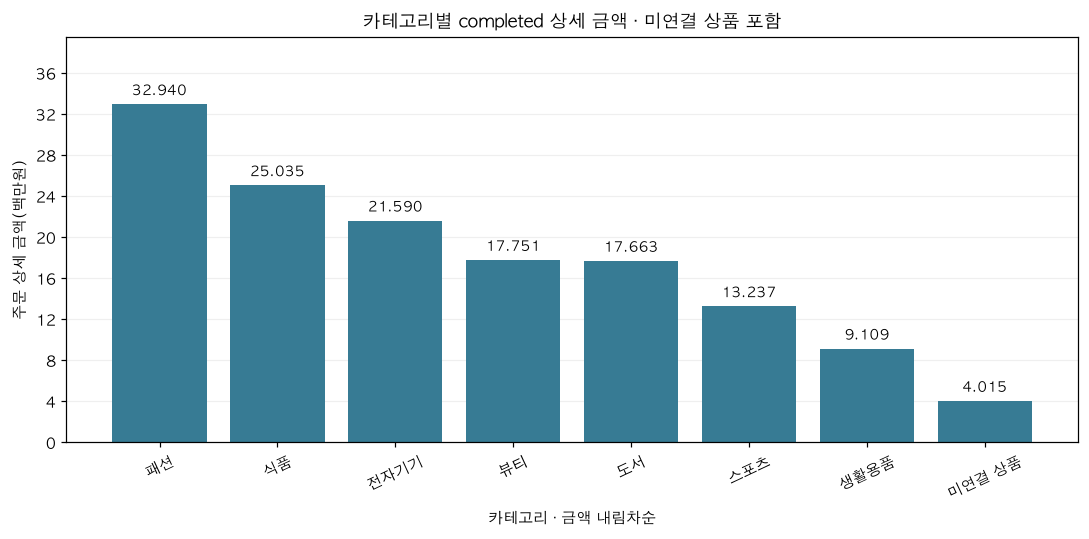

저장: graph01.png


In [5]:
category_path = plot_category_sales(category_sales)
print('저장:',category_path.name)

### 그래프 1 기록

### 원본 집계값

- completed 상세 446행·141,340,000원이며 미연결 상품 4,015,000원을 포함함

### 결과 관찰

- 패션 32,940,000원(23.31%)이 가장 크고 식품 25,035,000원보다 7,905,000원 큼

### 나의 해석과 판단

- 금액 차이는 확인되지만 구매 선호나 수익성 차이라고 단정할 근거는 부족함

### 업무·분석적 의미

- 카테고리별 실제 판매 수량·단가·고액 상세 구성을 함께 확인할 필요가 있음

### 한계와 추가 확인 사항

- 미연결 상품의 실제 카테고리는 알 수 없으며 할인·환불·원가를 반영한 회계 매출이나 이익이 아님

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [6]:
display(monthly_sales[['order_month','completed_amount','completed_order_count','average_completed_order_amount','coverage']])
print('날짜 미상 금액:', f'{invalid_date_sales.line_total.sum():,.0f}원')
# 전체 주문에서도 빈 기간인지, completed 상세만 없는 것인지 구분함
all_order_month_count = orders.dropna(subset=['order_date']).assign(month=lambda d:d.order_date.dt.to_period('M')).groupby('month').size()
completed_order_month_count = orders.loc[orders.order_status.eq('completed') & orders.order_date.notna()].assign(month=lambda d:d.order_date.dt.to_period('M')).groupby('month').size()
coverage = monthly_sales[['order_month','coverage']].copy()
coverage['전체 주문 기록 수'] = coverage.order_month.map(all_order_month_count).fillna(0).astype(int)
coverage['completed 주문 기록 수'] = coverage.order_month.map(completed_order_month_count).fillna(0).astype(int)
coverage['상세 있는 completed 주문 수'] = monthly_sales.completed_order_count
print('아래 주문 기록 수 0은 현재 파일에서 센 행 수이며, 실제 영업 금액 0의 증거는 아님')
display(coverage)
print('월별 주문 수·평균의 분모: 상세가 있고 유효 주문일이 있는 고유 completed 주문')
print('날짜 미상 고유 주문:',invalid_date_sales.order_id.nunique(),'건, 월별 선에서 제외하고 금액 보존')


,order_month,completed_amount,completed_order_count,average_completed_order_amount,coverage
0,2025-07,9561000.0,11.0,8.691818e+05,상세 관측 있음
1,2025-08,9362000.0,17.0,5.507059e+05,상세 관측 있음
2,2025-09,5299000.0,4.0,1.324750e+06,상세 관측 있음
3,2025-10,12629000.0,17.0,7.428824e+05,상세 관측 있음
4,2025-11,9583000.0,16.0,5.989375e+05,상세 관측 있음
5,2025-12,8581000.0,12.0,7.150833e+05,상세 관측 있음
6,2026-01,8135000.0,9.0,9.038889e+05,상세 관측 있음
7,2026-02,7689000.0,12.0,6.407500e+05,상세 관측 있음
8,2026-03,7247000.0,13.0,5.574615e+05,상세 관측 있음
9,2026-04,11459000.0,14.0,8.185000e+05,상세 관측 있음


날짜 미상 금액: 1,903,000원
아래 주문 기록 수 0은 현재 파일에서 센 행 수이며, 실제 영업 금액 0의 증거는 아님


,order_month,coverage,전체 주문 기록 수,completed 주문 기록 수,상세 있는 completed 주문 수
0,2025-07,상세 관측 있음,19,11,11.0
1,2025-08,상세 관측 있음,26,18,17.0
2,2025-09,상세 관측 있음,12,4,4.0
3,2025-10,상세 관측 있음,22,17,17.0
4,2025-11,상세 관측 있음,23,16,16.0
5,2025-12,상세 관측 있음,23,12,12.0
6,2026-01,상세 관측 있음,26,9,9.0
7,2026-02,상세 관측 있음,19,12,12.0
8,2026-03,상세 관측 있음,22,13,13.0
9,2026-04,상세 관측 있음,26,14,14.0


월별 주문 수·평균의 분모: 상세가 있고 유효 주문일이 있는 고유 completed 주문
날짜 미상 고유 주문: 2 건, 월별 선에서 제외하고 금액 보존


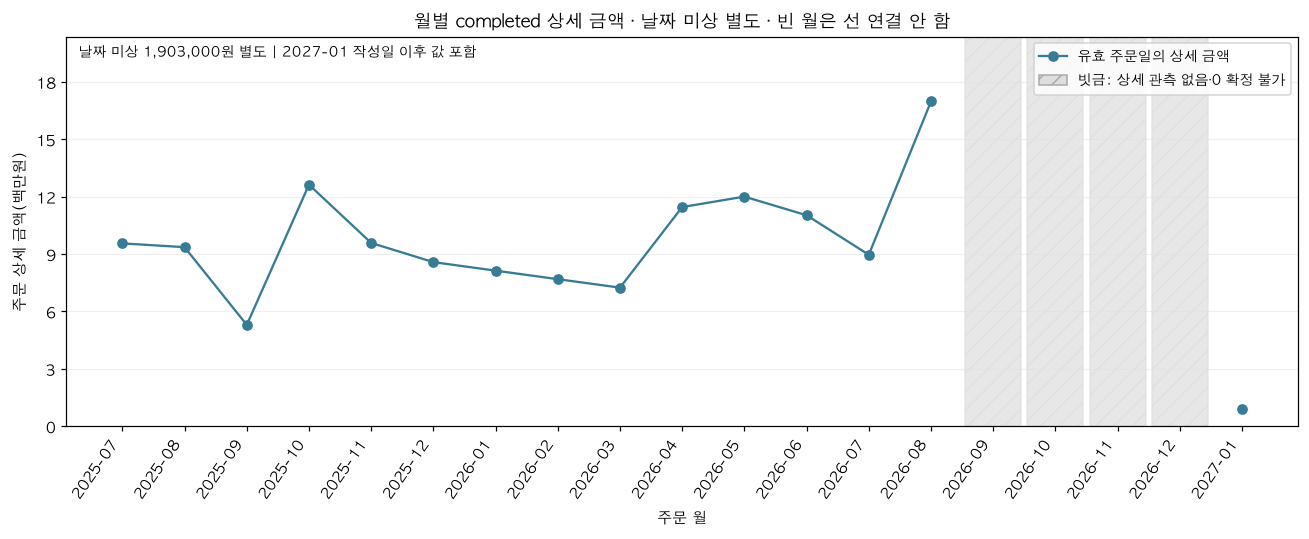

저장: graph02.png


In [7]:
monthly_path = plot_monthly_sales(monthly_sales)
print('저장:',monthly_path.name)

### 그래프 2 기록

### 원본 집계값

- 유효 날짜 139,437,000원 + 날짜 미상 1,903,000원 = completed 원본 141,340,000원임
- 평균의 분모는 상세가 있고 유효 주문일이 있는 고유 주문이며 날짜 미상 2건과 상세 없는 completed 1건은 월별 금액·평균에서 제외함

### 결과 관찰

- 2026-08은 16,980,000원·15건으로 관측 월 중 가장 크고 7월은 8,966,000원·8건임
- 2026-09~12는 전체 주문 파일에도 기록이 없어 선을 끊었으며 실제 영업 금액이 0인지는 알 수 없음

### 나의 해석과 판단

- 7→8월 평균 주문 금액은 1,120,750→1,132,000원으로 비슷하고 주문 수는 8→15건으로 차이가 더 큼
- 관측 구간에서 오르내림이 반복되어 지속적인 증가나 감소라고 판단하기 어려움

### 업무·분석적 의미

- 월별 금액뿐 아니라 고유 주문 수·평균 금액·카테고리 구성을 함께 비교할 필요가 있음

### 한계와 추가 확인 사항

- 2027-01 completed 1건은 작성일 이후 값이며 실제 거래로 확정할 수 없음, 첫·마지막 달 관측 범위와 날짜 원본 확인이 필요함
- 전체 주문의 작성일 이후 값 2건 중 나머지 1건은 completed가 아니므로 금액 그래프에 포함하지 않음
- 현재 패턴만으로 광고 효과나 계절성을 원인으로 단정하지 않음

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [8]:
display(products.price.describe().to_frame('상품 마스터 가격(원)'))
prices = products.price.to_numpy()
hist_counts, hist_edges = np.histogram(prices,bins=np.linspace(0,prices.max(),21))
hist_table = pd.DataFrame({'구간 시작(이상)':hist_edges[:-1],'구간 끝(미만·마지막 이하)':hist_edges[1:],'상품 수':hist_counts})
display(hist_table)
print('200,000원 이하:',int((prices<=200_000).sum()),'초과:',int((prices>200_000).sum()))
zoom_prices = prices[prices<=200_000]
zoom_counts, zoom_edges = np.histogram(zoom_prices,bins=np.linspace(0,200_000,21))
zoom_hist_table = pd.DataFrame({'구간 시작(이상)':zoom_edges[:-1],'구간 끝(미만·마지막 이하)':zoom_edges[1:],'상품 수':zoom_counts})
print('확대 패널 원본 집계: 0~200,000원, 구간 폭 10,000원, 표본 95개')
display(zoom_hist_table)
print('전체 패널 구간 폭:',hist_edges[1]-hist_edges[0],'원 / 확대 패널:',zoom_edges[1]-zoom_edges[0],'원')
assert hist_counts.sum()==len(prices) and zoom_counts.sum()==len(zoom_prices)


,상품 마스터 가격(원)
count,9.600000e+01
mean,2.048958e+05
std,1.011848e+06
min,5.000000e+03
25%,5.275000e+04
50%,9.450000e+04
75%,1.532500e+05
max,9.999999e+06


,구간 시작(이상),구간 끝(미만·마지막 이하),상품 수
0,0.00,499999.95,95
1,499999.95,999999.90,0
2,999999.90,1499999.85,0
3,1499999.85,1999999.80,0
4,1999999.80,2499999.75,0
5,2499999.75,2999999.70,0
6,2999999.70,3499999.65,0
7,3499999.65,3999999.60,0
8,3999999.60,4499999.55,0
9,4499999.55,4999999.50,0


200,000원 이하: 95 초과: 1
확대 패널 원본 집계: 0~200,000원, 구간 폭 10,000원, 표본 95개


,구간 시작(이상),구간 끝(미만·마지막 이하),상품 수
0,0.0,10000.0,1
1,10000.0,20000.0,5
2,20000.0,30000.0,6
3,30000.0,40000.0,5
4,40000.0,50000.0,5
5,50000.0,60000.0,7
6,60000.0,70000.0,1
7,70000.0,80000.0,10
8,80000.0,90000.0,5
9,90000.0,100000.0,6


전체 패널 구간 폭: 499999.95 원 / 확대 패널: 10000.0 원


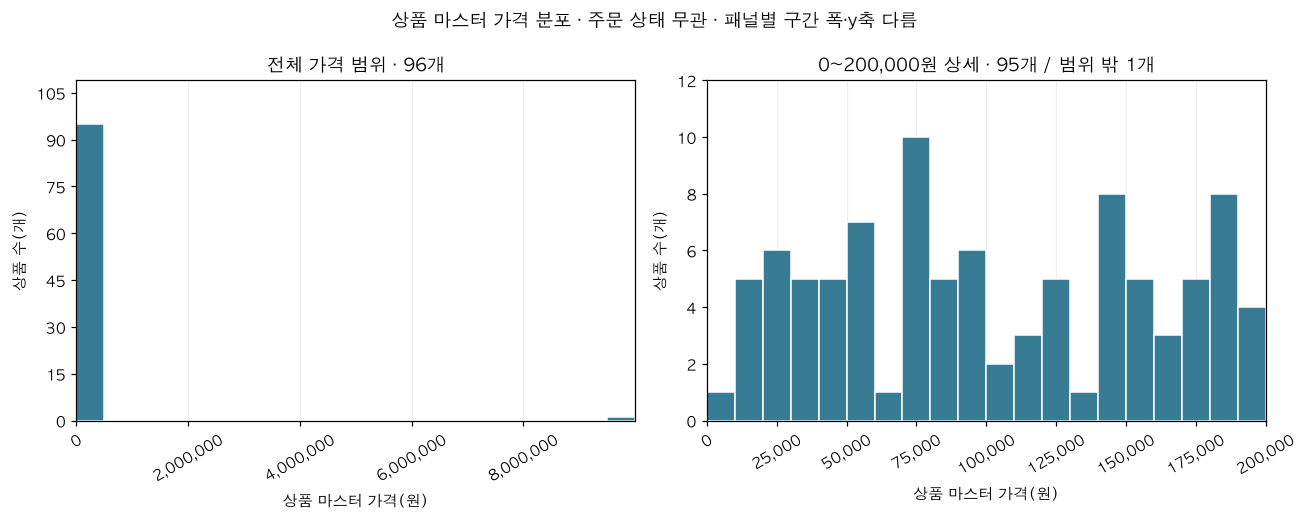

저장: graph03.png


In [9]:
price_hist_path = plot_product_price_hist(products)
print('저장:',price_hist_path.name)

### 가격 분포 기록

- 원본 집계값: 상품 96개, 최솟값 5,000원·중앙값 94,500원·최댓값 9,999,999원임
- 결과 관찰: 20만원 이하 95개와 초과 1개로 나뉘고 평균은 약 204,896원임
- 나의 해석과 판단: 큰 값 1개로 전체 그래프에서 나머지 분포를 보기 어려워 전체 범위 옆에 20만원 이하 구간을 함께 표시함
- 업무·분석적 의미: 평균 가격만 활용하기 전에 중앙값과 원본 가격을 함께 확인할 필요가 있음
- 한계와 추가 확인 사항: 확대 패널은 1개를 제외하며 두 패널의 y축이 다름, 구간 폭도 달라 패널 간 막대 높이를 직접 비교하지 않으며 큰 가격이 오류인지는 원본 확인이 필요함

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
- 어떤 인상은 bins 선택에 따라 달라지는가?

- 실제 비교에서 bins=10·20·30 모두 첫 구간에 95개가 포함되어 큰 가격 1개와 나머지 상품이 분리되는 패턴은 같음
- 세 비교만으로 20만원 이하의 세부 가격 집중 구간을 알 수 없어 대표 그래프에서 별도 범위를 확인함

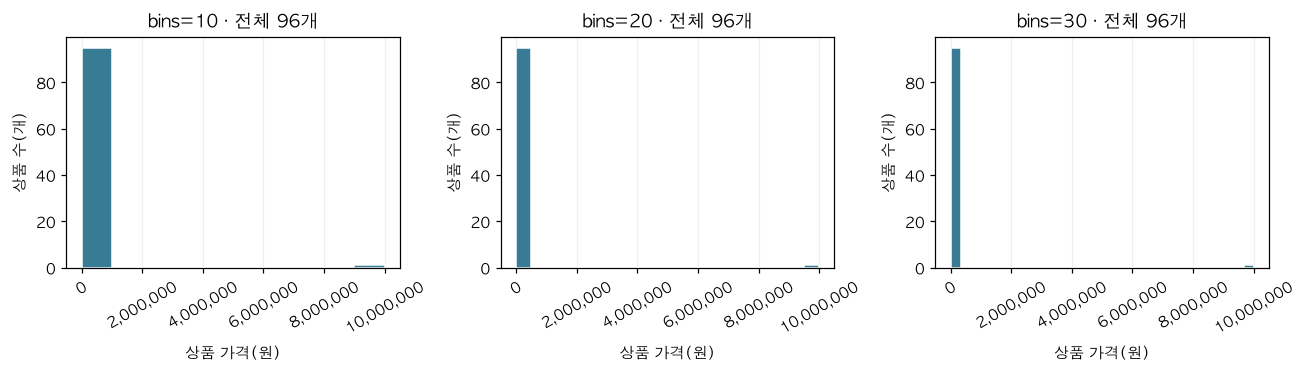

bins=10/20/30 모두 첫 구간 상품 수: [95, 95, 95]


In [10]:
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,bins in zip(axes,[10,20,30]):
    counts,edges=np.histogram(prices,bins=np.linspace(0,prices.max(),bins+1))
    ax.hist(prices,bins=edges,color='#377B94',edgecolor='white')
    assert counts.sum()==len(prices)
    ax.set(title=f'bins={bins} · 전체 {len(prices)}개',xlabel='상품 가격(원)',ylabel='상품 수(개)')
    ax.tick_params(axis='x',rotation=30);money_axis(ax,'x')
finish(fig,'price_bins_comparison.png')
print('bins=10/20/30 모두 첫 구간 상품 수:', [int(np.histogram(prices,bins=np.linspace(0,prices.max(),k+1))[0][0]) for k in [10,20,30]])

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [11]:
display(product_sales[['price','completed_quantity','completed_amount']].describe())
print('표시가격 미연결 상품 그룹:',int(product_sales.price.isna().sum()),'금액:',product_sales.loc[product_sales.price.isna(),'completed_amount'].sum())

,price,completed_quantity,completed_amount
count,9.500000e+01,100.000000,1.000000e+02
mean,2.066105e+05,13.750000,1.413400e+06
std,1.017076e+06,9.078084,1.254587e+06
min,5.000000e+03,1.000000,6.300000e+04
25%,5.350000e+04,7.000000,4.887500e+05
50%,9.600000e+04,13.000000,1.214000e+06
75%,1.535000e+05,17.250000,1.901000e+06
max,9.999999e+06,70.000000,6.771000e+06


표시가격 미연결 상품 그룹: 5 금액: 4015000.0


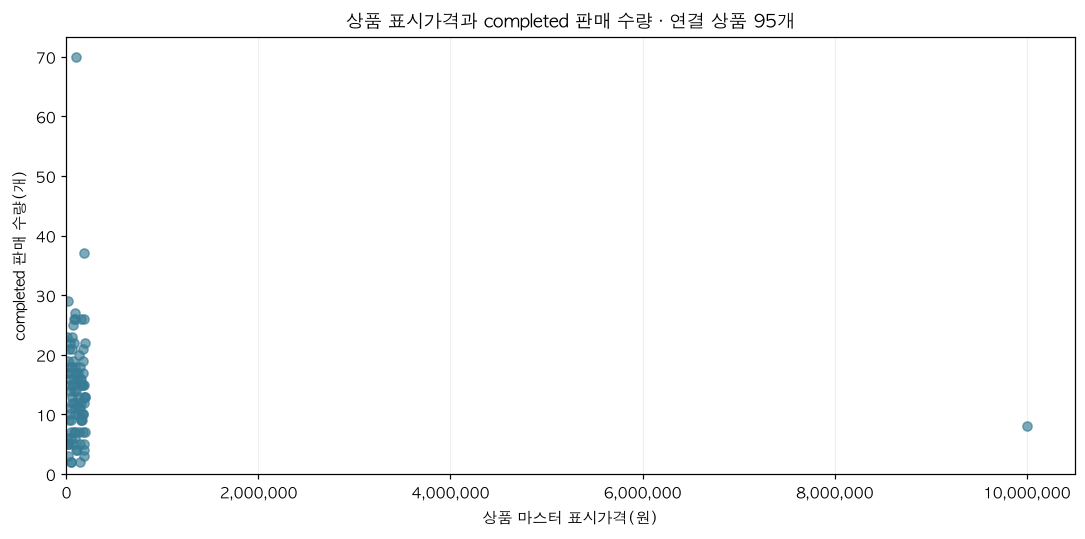

In [12]:
scatter_path = plot_price_quantity_scatter(product_sales)

### 그래프 3 기록

- 이 절은 공식 Notebook의 산점도 보조 실습이며 최종 답안의 대표 그래프 3은 가격 히스토그램으로 선택함
- **관찰:** completed 연결 상품은 95개이며 표시가격 9,999,999원 상품의 판매 수량은 8개임
- **해석:** 큰 표시가격 때문에 나머지 점이 왼쪽에 몰려 보여 전체 산점도만으로 관계를 판단하기 어려움
- **한계:** 상품 미연결 5개 ID 그룹·4,015,000원은 표시가격을 알 수 없어 점에서 제외됨, 표시가격은 실제 판매 단가와 다름
- **다음 질문:** 이상 가격 원본과 카테고리·실제 판매 단가·판매 기간을 함께 확인할 필요가 있음

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [13]:
# 원본 고객 ID는 출력하지 않고 금액 순위만 표시함
top_display=customer_sales.head(10).drop(columns='customer_id').reset_index(drop=True)
top_display.index=range(1,len(top_display)+1)
top_display.index.name='금액 순위'
display(top_display)

,completed_order_count,completed_amount,average_completed_order_amount
금액 순위,,,
1,3,6702000.0,2.234000e+06
2,4,5204000.0,1.301000e+06
3,3,4311000.0,1.437000e+06
4,4,4001000.0,1.000250e+06
5,6,3977000.0,6.628333e+05
6,2,3966000.0,1.983000e+06
7,4,3808000.0,9.520000e+05
8,4,3656000.0,9.140000e+05
9,4,3201000.0,8.002500e+05


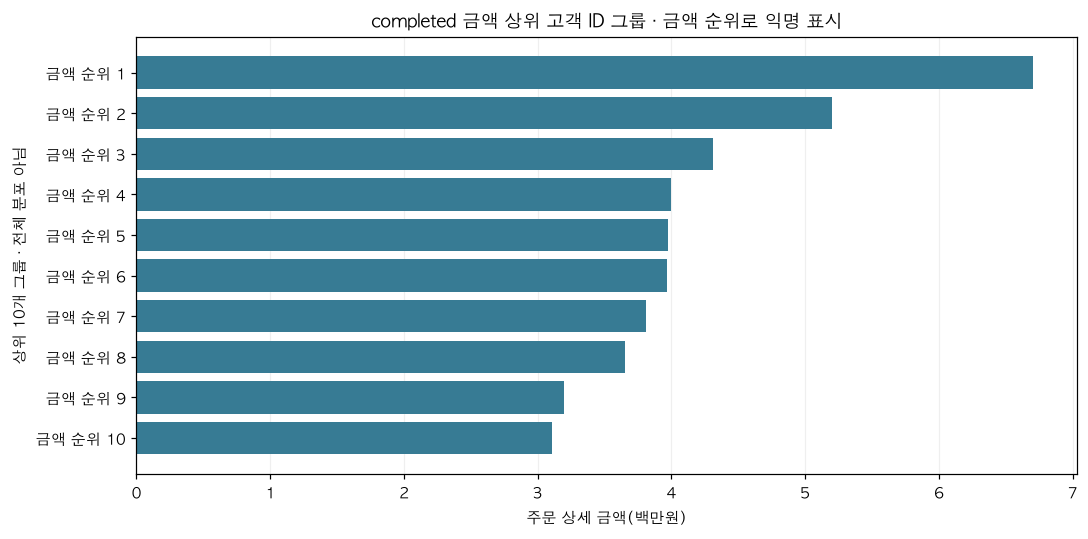

In [14]:
top_customer_path = plot_top_customers(customer_sales)

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

- 상위 금액 그룹은 6,702,000원·3건이고 주문 수가 가장 많은 상위 10위 내 그룹은 6건임
- 구매 금액 순위와 주문 횟수가 같지 않아 금액 순위만으로 충성 고객을 정할 근거는 부족함
- 고객 이름·원본 ID를 출력하지 않고 순위로 표시함, 고객 마스터 미연결 상세 376,000원도 있어 고객 정보 확인이 필요함

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [15]:
display(order_status)

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


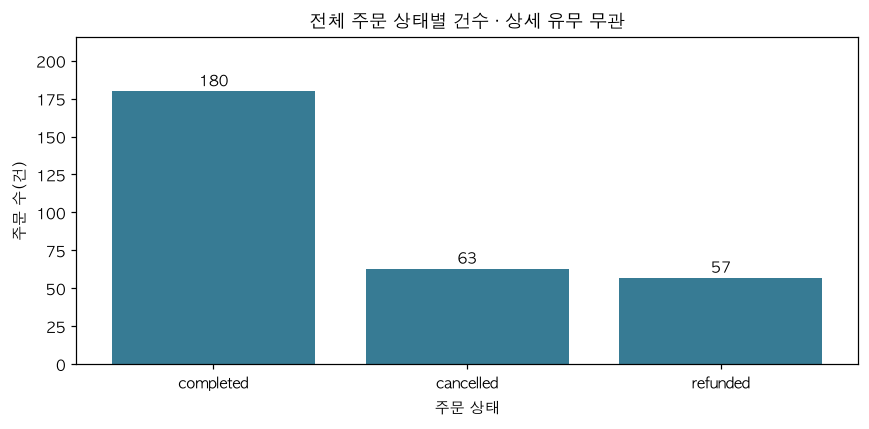

In [16]:
order_status_path = plot_order_status(order_status)

### 주문 상태 해석

- 전체 주문 300건 중 completed 180건·cancelled 63건·refunded 57건임
- 주문 상태별 규모를 보여 주며 금액 그래프의 completed 범위와 구분함
- completed 180건 중 상세가 있는 주문은 179건임, 상태별 금액이나 취소·환불 이유는 이 그래프에서 알 수 없음

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

In [17]:
artist_validation = pd.DataFrame(artist_checks)
display(artist_validation)
assert artist_validation.passed.all()
# 축 범위·시간 빈칸·히스토그램 총수도 수치로 점검함
assert figures['category'].axes[0].get_ylim()[0]==0
assert figures['monthly'].axes[0].get_ylim()[0]==0
assert len(monthly_sales)==len(calendar)
assert monthly_sales.completed_amount.isna().equals(~monthly_sales.order_month.isin(monthly_observed.index))
assert hist_table['상품 수'].sum()==len(products)
print('축 0 시작 / 연속 월 달력 / 미관측 NaN / 히스토그램 96개 보존 PASS')
assert figures['category'].axes[0].get_ylim()[1] >= category_sales.completed_amount.max()/1e6
assert figures['monthly'].axes[0].get_ylim()[1] >= monthly_sales.completed_amount.max()/1e6
for ax in figures['price'].axes:
    assert ax.get_ylim()[0]==0
    assert ax.get_ylim()[1] >= max(patch.get_height() for patch in ax.patches)
    assert ax.get_xlim()[0] <= min(patch.get_x() for patch in ax.patches)+1e-6
    assert ax.get_xlim()[1] >= max(patch.get_x()+patch.get_width() for patch in ax.patches)-1e-6
print('대표 그래프 상단·구간 경계 잘림 없음 PASS')


,검증,passed
0,막대 높이×백만원 = 집계표,True
1,선 y값×백만원 = 월 집계표,True
2,선 x값 = 월 시간 순서,True
3,히스토그램 전체 가격 범위 · 96개: 구간 빈도,True
4,히스토그램 전체 가격 범위 · 96개: 표시 집계표,True
5,히스토그램 전체 가격 범위 · 96개: 구간 경계,True
6,히스토그램 전체 가격 범위 · 96개: 막대 시작점,True
7,히스토그램 전체 가격 범위 · 96개: 막대 폭,True
8,히스토그램 전체 가격 범위 · 96개: 막대 높이,True
9,히스토그램 전체 가격 범위 · 96개: 표본 수,True


축 0 시작 / 연속 월 달력 / 미관측 NaN / 히스토그램 96개 보존 PASS
대표 그래프 상단·구간 경계 잘림 없음 PASS


## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

- 이 제출본은 같은 Notebook 함수로 그래프 6개를 재생성하고 PNG 해시를 비교함
- 가이드 STEP 8의 선택 사항인 별도 scripts/run_visualization.py 실행은 수행하지 않음
- 그래프 저장 위치는 제출용 images이며 집계 CSV와 요약 보고서는 수업 폴더 reports/chapter07에 저장함

In [18]:
# 같은 함수를 다시 실행하고 PNG가 같은지 확인함
paths = [FIGURE_DIR / name for name in ['graph01.png','graph02.png','graph03.png','price_quantity.png','top_customers.png','order_status.png']]
before_hashes = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
for fn,table in [(plot_category_sales,category_sales),(plot_monthly_sales,monthly_sales),(plot_product_price_hist,products),(plot_price_quantity_scatter,product_sales),(plot_top_customers,customer_sales),(plot_order_status,order_status)]:
    fn(table,show=False)
assert before_hashes == {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
for label,table in [('category',category_sales),('monthly',monthly_sales),('histogram',hist_table),('histogram_zoom',zoom_hist_table),('monthly_coverage',coverage),('validation',validation)]:
    table.to_csv(REPORT_DIR / f'ch07_{label}.csv',index=False)
report = f'''# Chapter07 실행 검증
completed 상세 {len(items)}행, 금액 {completed_total:,.0f}원
월별 유효일 금액 {monthly_sales.completed_amount.sum():,.0f}원 + 날짜 미상 {invalid_date_sales.line_total.sum():,.0f}원
범례·단위·월 순서 확인, 빈 월은 NaN으로 보존
카테고리·월별 금액/주문 수 CSV 독립 재계산과 그래프 artist 값 일치
전체·확대 히스토그램 집계표/구간 경계/막대 폭 일치
대표 그래프를 포함한 6개 PNG 재생성 SHA-256 일치
'''
(REPORT_DIR / 'ch07_visualization_summary.md').write_text(report,encoding='utf-8')
print(report)

# Chapter07 실행 검증
completed 상세 446행, 금액 141,340,000원
월별 유효일 금액 139,437,000원 + 날짜 미상 1,903,000원
범례·단위·월 순서 확인, 빈 월은 NaN으로 보존
카테고리·월별 금액/주문 수 CSV 독립 재계산과 그래프 artist 값 일치
전체·확대 히스토그램 집계표/구간 경계/막대 폭 일치
대표 그래프를 포함한 6개 PNG 재생성 SHA-256 일치



## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유

- 월별 선그래프를 선택함, 빈 기간을 0으로 처리하거나 2027년 값을 이어 그리면 추세를 잘못 읽을 수 있음을 보여 줌

### 그래프에서 직접 확인한 사실

- 2026-08 금액이 관측 월 중 가장 크며 2026-09~12는 completed 상세 관측이 없음

### 내가 해석한 내용

- 7→8월에는 평균 주문 금액보다 주문 수 차이가 컸지만 그 이유는 현재 데이터만으로 알 수 없음

### 그래프만으로 말할 수 없는 것

- 광고 효과·계절성·가격 변화의 인과 효과·고객 충성도·순이익은 단정할 수 없음

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 막대·선 금액축과 수량축은 0에서 시작함
- 단위: 금액은 백만원 또는 원, 수량은 개, 주문은 건으로 표시함
- 정렬: 카테고리는 금액 내림차순, 월은 연속 달력 순서임
- 범위: 날짜 미상 별도, 빈 월 NaN, 전체 가격과 확대 범위·표본 수·서로 다른 y축을 명시함
- 개인정보: 고객 이름·원본 ID를 표와 그래프에 표시하지 않음

### 다음 분석에서 확인하고 싶은 질문

- 날짜 미상과 2027년 주문일을 원본에서 확인하면 관측 월 범위와 월별 금액이 어떻게 바뀌는가?

---

## 완료 체크

- [ ] 질문을 그래프보다 먼저 정했습니다.
- [ ] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [ ] 집계 검증표의 `passed`를 확인했습니다.
- [ ] 대표 그래프 3개 이상을 만들었습니다.
- [ ] 그래프와 원본 집계값을 교차 확인했습니다.
- [ ] 축·단위·정렬·범위를 확인했습니다.
- [ ] 관계를 원인으로 단정하지 않았습니다.
- [ ] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [ ] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [ ] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

## ChatGPT 활용과 직접 확인

- 사용한 AI 도구: ChatGPT
- 요청 내용 요약: Chapter 05 processed로 질문 3개 이상·그래프 3개 이상을 만들고 집계값·축·시간 순서·개인정보·해석 한계를 확인하도록 요청함
- 제안 내용: 카테고리 막대·월별 선·가격 히스토그램을 대표 그래프로 사용하고 전체 가격과 확대 범위를 함께 보여 주는 코드 제안을 받음
- 수정한 내용: 상품 미연결 별도 그룹, 날짜 미상 금액, 미관측 월 NaN, 작성일 이후 값과 확대 패널 표본 수를 명시함
- 검증 결과: Chapter05 재생성 파일 해시·CSV 독립 계산·그래프 값 비교·6개 PNG 재생성 일치를 확인함
- 해석 기준: 데이터에 없는 선호·광고·계절성·인과관계 설명은 사용하지 않음

# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

> 이 내용을 `chapter07.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
이름: 장태원  
GitHub ID: pmsky1  
작성일: 2026-10-24  
최종 Notebook URL: https://github.com/pmsky1/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb  

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 상세 금액은 얼마나 다른가? | 막대그래프 | 같은 단위의 범주별 크기를 0 기준에서 비교하기 쉬움 |
| 월별 completed 금액과 주문 수 차이는 어떻게 나타나는가? | 선그래프 | 시간 순서와 빈 기간을 함께 확인할 수 있음, 주문 수는 집계표로 비교함 |
| 상품 마스터 가격은 어떤 범위에 분포하며 큰 값의 영향은 어떤가? | 히스토그램 | 개별 상품 가격을 구간별 빈도로 확인하고 전체·확대 범위를 비교할 수 있음 |

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값

- completed 상세 446행·141,340,000원이며 카테고리 합계와 일치함, 미연결 상품 4,015,000원 포함함

### 결과 관찰

- 패션 32,940,000원(23.31%)으로 가장 크고 식품 25,035,000원보다 7,905,000원 큼

### 나의 해석과 판단

- 금액 차이는 확인되지만 선호도나 수익성 차이라고 판단할 근거는 부족함

### 업무·분석적 의미

- 카테고리별 실제 판매 수량·단가·고액 상세 구성을 함께 확인할 필요가 있음

### 한계와 추가 확인 사항

- 미연결 상품 금액의 실제 카테고리는 알 수 없으며 할인·환불·원가를 반영한 회계 매출이나 이익이 아님

## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값

- 유효 날짜 합계 139,437,000원 + 날짜 미상 1,903,000원 = 원본 141,340,000원임
- 월별 평균의 분모는 상세가 있는 고유 completed 주문이며, 날짜 미상 2건과 상세 없는 1건은 월별 금액·평균에서 제외함

### 결과 관찰

- 2026-08 16,980,000원·15건이 관측 월 중 최대임, 7월은 8,966,000원·8건임

### 나의 해석과 판단

- 7→8월 평균 주문 금액은 1,120,750→1,132,000원으로 비슷하고 주문 수 차이가 더 크게 나타남
- 관측 월마다 증가·감소가 반복되어 지속적인 상승 추세라고 판단하기 어려움

### 업무·분석적 의미

- 금액 증감만 보지 말고 고유 주문 수·평균 금액·월별 카테고리 구성을 함께 비교할 필요가 있음

### 한계와 추가 확인 사항

- 2026-09~12는 전체 주문 파일에도 기록이 없어 선을 끊었으며 실제 영업 금액 0인지는 확정할 수 없음, 날짜 미상·2027-01 작성일 이후 값·첫/마지막 달 관측 기간을 확인해야 하며 장기 추세나 원인을 단정하지 않음

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값

- 전체 상품 96개, 가격 5,000~9,999,999원, 중앙값 94,500원·평균 약 204,896원임

### 결과 관찰

- 20만원 이하 95개와 초과 1개임, bins=10·20·30 모두 전체 범위의 첫 구간에 95개가 포함됨

### 나의 해석과 판단

- 전체 히스토그램만으로 보통 가격대의 분포를 읽기 어려워 전체와 20만원 이하 확대 범위를 함께 확인함

### 업무·분석적 의미

- 평균 가격만 사용하기 전에 중앙값과 극단값을 확인하고 원본 가격 확인 대상으로 정할 필요가 있음

### 한계와 추가 확인 사항

- 확대 패널에서 1개가 제외되고 구간 폭·y축이 달라 패널 간 막대 높이를 직접 비교하지 않음, 상품 표시가격은 실제 판매 단가가 아니며 큰 값이 오류인지 확인 필요함

## 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점

- 미연결 상품을 빼면 합계가 줄어 별도 막대로 포함함, 독립 CSV 계산 및 그래프 artist 값을 집계표와 대조함
- 날짜 미상을 월별 0으로 바꾸지 않고 별도 금액으로 표시함, 관측 없는 월은 NaN과 빗금으로 표시함
- 가격 극단값은 삭제하지 않고 전체 범위를 유지한 채 표본 수가 다른 확대 패널을 함께 보여 줌
- 고객 순위는 익명으로 표시하며 단일 계열 그래프는 축·제목으로 설명하고 월별 그래프는 범례를 표시함

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유

- 월별 선그래프를 선택함, 빈 기간과 날짜 이상을 표시하는 방식에 따라 같은 데이터도 다르게 보일 수 있기 때문임

### 그래프가 보여 준 사실

- 패션 금액이 가장 크고 관측 월 중 2026-08 금액이 가장 큼, 상품 가격 96개 중 95개가 20만원 이하임

### 그래프만으로 말할 수 없는 것

- 구매 선호·광고 효과·계절성·가격의 인과 효과와 순이익은 알 수 없음

### 다음 분석에서 확인할 질문

- 날짜 미상·작성일 이후 주문일·큰 상품 가격을 원본에서 확인하면 월별 패턴과 가격 분포가 어떻게 바뀌는가?

## 최종 체크
- [ ] 그래프와 수치를 교차 검증했습니다.
- [ ] 관찰과 해석을 구분했습니다.
- [ ] 업무적 의미와 한계를 작성했습니다.
- [ ] 최종 Notebook URL을 제출합니다.